In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv('/kaggle/input/datasets/mirajdeepbhandari/polynomial-regression/Ice_cream selling data.csv')
print(df.shape)
df.head()

(49, 2)


,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [3]:
X = df[['Temperature (°C)']]
y = df['Ice Cream Sales (units)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

poly = PolynomialFeatures(degree=2, include_bias=False)
Xp_train = poly.fit_transform(X_train)
Xp_test = poly.transform(X_test)

scaler = StandardScaler()
Xs_train = scaler.fit_transform(Xp_train)
Xs_test = scaler.transform(Xp_test)

y_tr = y_train.values
y_te = y_test.values

In [4]:
def evaluate(w, b, name):
    pred = Xs_test @ w + b
    rmse = np.sqrt(mean_squared_error(y_te, pred))
    r2 = r2_score(y_te, pred)
    print(f'{name} -> Test RMSE: {rmse:.2f} | Test R2: {r2:.3f}')

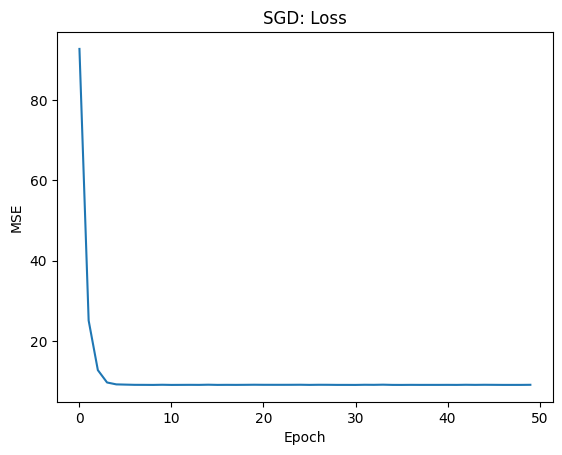

SGD -> Test RMSE: 3.78 | Test R2: 0.849


In [5]:
def sgd(X, y, lr=0.01, epochs=50, seed=42):
    rng = np.random.default_rng(seed)
    m, n = X.shape
    w = np.zeros(n)
    b = 0.0
    history = []
    for _ in range(epochs):
        for i in rng.permutation(m):
            error = (X[i] @ w + b) - y[i]
            w -= lr * 2 * error * X[i]
            b -= lr * 2 * error
        history.append(np.mean((X @ w + b - y) ** 2))
    return w, b, history

w, b, hist = sgd(Xs_train, y_tr)

plt.plot(hist)
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('SGD: Loss')
plt.show()

evaluate(w, b, 'SGD')